**KMeans Clustering** 

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler

In [ ]:
df = pd.read_csv("/content/income.csv")
df

,Name,Age,Income($)
0,Rob,27,70000
1,Michael,29,90000
2,Mohan,29,61000
3,Ismail,28,60000
4,Kory,42,150000
5,Gautam,39,155000
6,David,41,160000
7,Andrea,38,162000
8,Brad,36,156000
9,Angelina,35,130000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   Name       22 non-null     object
 1   Age        22 non-null     int64 
 2   Income($)  22 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 660.0+ bytes


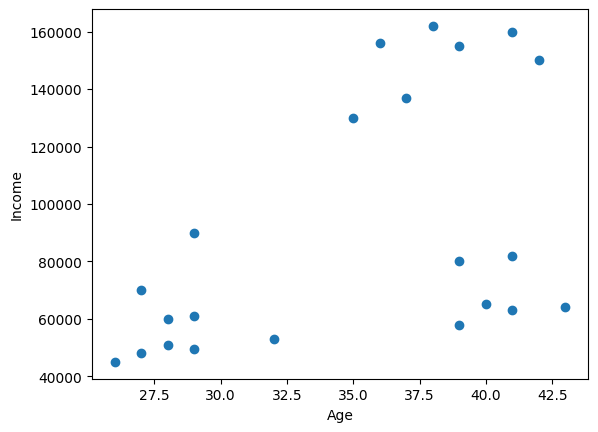

In [ ]:
plt.scatter(df['Age'],df['Income($)'])
plt.xlabel("Age")
plt.ylabel("Income")
plt.show()

In [ ]:
km = KMeans(n_clusters = 3)

In [ ]:
y_pred = km.fit_predict(df[['Age', 'Income($)']])

In [ ]:
print(y_pred)
print(len(y_pred))

[1 1 1 1 2 2 2 2 2 0 0 1 1 1 1 1 1 1 1 1 1 1]
22


In [ ]:
df['Cluster'] = y_pred

In [ ]:
df

,Name,Age,Income($),Cluster
0,Rob,27,70000,1
1,Michael,29,90000,1
2,Mohan,29,61000,1
3,Ismail,28,60000,1
4,Kory,42,150000,2
5,Gautam,39,155000,2
6,David,41,160000,2
7,Andrea,38,162000,2
8,Brad,36,156000,2
9,Angelina,35,130000,0


In [ ]:
km.cluster_centers_   # centroid location

array([[3.60000000e+01, 1.33500000e+05],
       [3.32000000e+01, 6.26333333e+04],
       [3.92000000e+01, 1.56600000e+05]])

In [ ]:
df1 = df[df['Cluster']==0]
df2 = df[df['Cluster']==1]
df3 = df[df['Cluster']==2]

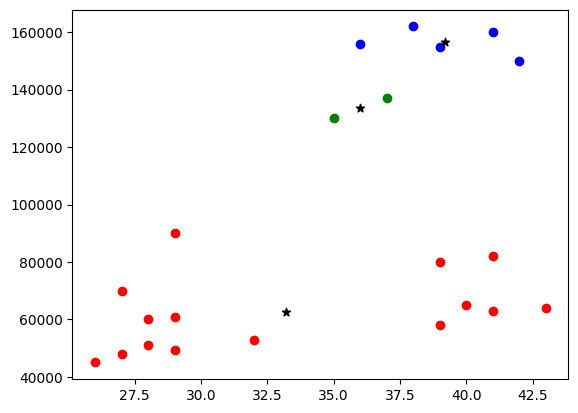

In [ ]:
plt.scatter(df1['Age'],df1['Income($)'], color = 'green')
plt.scatter(df2['Age'],df2['Income($)'], color = 'red')
plt.scatter(df3['Age'],df3['Income($)'], color = 'blue')
plt.scatter(km.cluster_centers_[:,0], km.cluster_centers_[:,1], color = 'black', marker = "*", label ='centroid')
plt.show()

In [ ]:
# feature scaling
# Preprocessing
scaler = MinMaxScaler()


In [ ]:
#from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

# Scaling Income
scaler.fit(df[['Income($)']])
df['Income($)'] = scaler.transform(df[['Income($)']])

# Scaling Age
scaler.fit(df[['Age']])
df['Age'] = scaler.transform(df[['Age']])


In [ ]:
df

,Name,Age,Income($),Cluster
0,Rob,0.058824,0.213675,1
1,Michael,0.176471,0.384615,1
2,Mohan,0.176471,0.136752,1
3,Ismail,0.117647,0.128205,1
4,Kory,0.941176,0.897436,2
5,Gautam,0.764706,0.940171,2
6,David,0.882353,0.982906,2
7,Andrea,0.705882,1.000000,2
8,Brad,0.588235,0.948718,2
9,Angelina,0.529412,0.726496,0


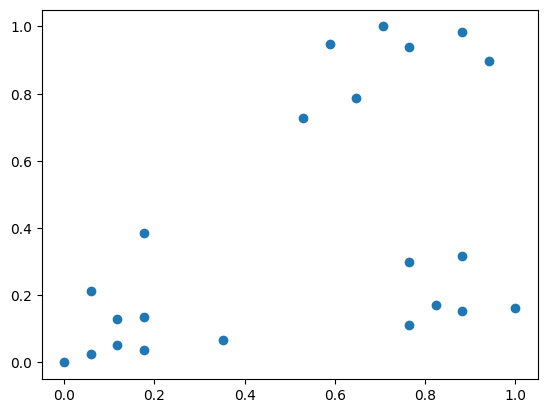

In [ ]:
plt.scatter(df.Age,df['Income($)'])

In [ ]:
km1 = KMeans(n_clusters = 3)
y_pred = km1.fit_predict(df[['Age','Income($)']])
y_pred

array([1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2],
      dtype=int32)

In [ ]:
df['Cluster'] = y_pred

In [ ]:
df

,Name,Age,Income($),Cluster
0,Rob,0.058824,0.213675,1
1,Michael,0.176471,0.384615,1
2,Mohan,0.176471,0.136752,1
3,Ismail,0.117647,0.128205,1
4,Kory,0.941176,0.897436,0
5,Gautam,0.764706,0.940171,0
6,David,0.882353,0.982906,0
7,Andrea,0.705882,1.000000,0
8,Brad,0.588235,0.948718,0
9,Angelina,0.529412,0.726496,0


In [ ]:
km1.cluster_centers_

array([[0.72268908, 0.8974359 ],
       [0.1372549 , 0.11633428],
       [0.85294118, 0.2022792 ]])

In [ ]:
df1 = df[df['Cluster']==0]
df2 = df[df['Cluster']==1]
df3 = df[df['Cluster']==2]

Text(0, 0.5, 'Income')

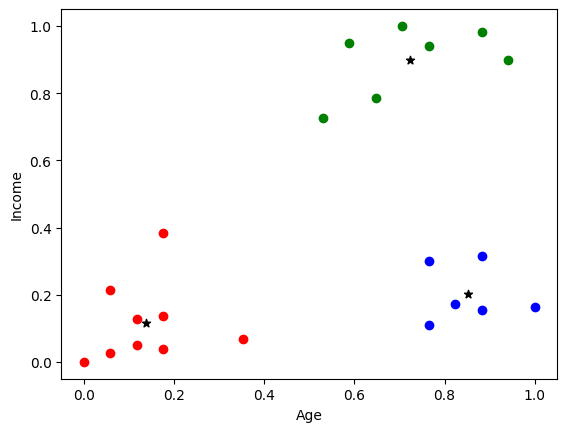

In [ ]:
plt.scatter(df1['Age'],df1['Income($)'], color = 'green')
plt.scatter(df2['Age'],df2['Income($)'], color = 'red')
plt.scatter(df3['Age'],df3['Income($)'], color = 'blue')
plt.scatter(km1.cluster_centers_[:,0], km1.cluster_centers_[:,1],
            color = 'black', marker = "*", label ='centroid')
plt.xlabel("Age")
plt.ylabel("Income")

In [ ]:
# Elbow method

sse = [] # minimum sse value will be tthe best k
k_rng = range(1, 10)
for k in k_rng:
  km = KMeans(n_clusters = k)
  km.fit(df[['Age', 'Income($)']])
  sse.append(km.inertia_)

**What is inertia_ in KMeans?**

It is the sum of squared distances between each data point and the centroid of its assigned cluster.

Also called within-cluster sum of squares (WCSS).
[WCSS Formula](https://docs.google.com/document/d/1fx_05m8RLPoHsxIQ-zeN9YSKaaaSWOdTKWsbNcb8p2M/edit?usp=sharing)

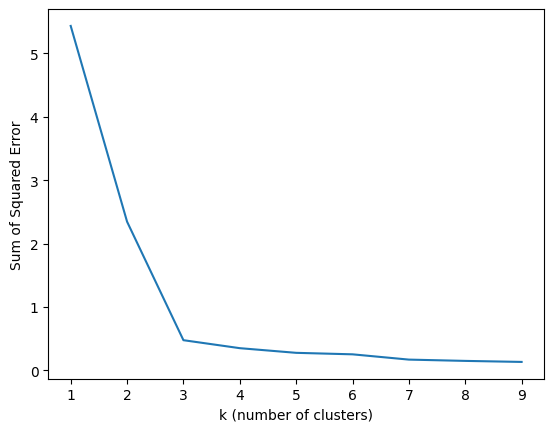

In [ ]:
plt.xlabel("k (number of clusters)")
plt.ylabel("Sum of Squared Error")
plt.plot(k_rng, sse)
plt.show()